CHURN PREDICTION

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

df = pd.read_csv('data/Telco_Churn.csv')
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:
df.head().T #to see all columns

,0,1,2,3,4
customerID,7590-VHVEG,5575-GNVDE,3668-QPYBK,7795-CFOCW,9237-HQITU
gender,Female,Male,Male,Male,Female
SeniorCitizen,0,0,0,0,0
Partner,Yes,No,No,No,No
Dependents,No,No,No,No,No
tenure,1,34,2,45,2
PhoneService,No,Yes,Yes,No,Yes
MultipleLines,No phone service,No,No,No phone service,No
InternetService,DSL,DSL,DSL,DSL,Fiber optic
OnlineSecurity,No,Yes,Yes,Yes,No


In [3]:
df.columns = df.columns.str.lower().str.replace(' ', '_')
categorical_columns = df.select_dtypes(include=['object','string','str']).columns

for c in categorical_columns:
    df[c] = df[c].str.lower().str.replace(' ', '_')

In [4]:
df.totalcharges = pd.to_numeric(df.totalcharges, errors='coerce') #ignore errors and convert to NaN
df.totalcharges = df.totalcharges.fillna(0) #replace NaN with 0 but better to do dropna

#df = df.dropna(subset=['totalcharges'])

In [5]:
#check if churn variable is useful
#here we have yes or no but we need numbers
#convert yes to 1 and no to 0
df.churn = (df.churn == 'yes').astype(int)


In [6]:
from sklearn.model_selection import train_test_split

In [7]:
df_full_train,df_test = train_test_split(df,test_size=0.2,random_state=1)

df_train,df_val = train_test_split(df_full_train,test_size=0.25,random_state=1)
# 20% of 80%
len(df_train),len(df_val),len(df_test)

(4225, 1409, 1409)

In [8]:
y_train = df_train.churn.values
y_val = df_val.churn.values
y_test = df_test.churn.values

In [9]:
del df_train['churn']
del df_val['churn']
del df_test['churn']

#to avoid using the variables when building the model

In [10]:
df_full_train = df_full_train.reset_index(drop=True)
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

In [11]:
df_full_train.isnull().sum() # no additional data preparation required

customerid          0
gender              0
seniorcitizen       0
partner             0
dependents          0
tenure              0
phoneservice        0
multiplelines       0
internetservice     0
onlinesecurity      0
onlinebackup        0
deviceprotection    0
techsupport         0
streamingtv         0
streamingmovies     0
contract            0
paperlessbilling    0
paymentmethod       0
monthlycharges      0
totalcharges        0
churn               0
dtype: int64

In [12]:
df_full_train.churn.value_counts(normalize=True)#percentage of churn and not churn
#27% churn rate
#can also do mean because it is binary dataset

churn
0    0.730032
1    0.269968
Name: proportion, dtype: float64

In [13]:
global_churn_rate = df_full_train.churn.mean()

In [14]:
numerical = ['tenure','monthlycharges','totalcharges'] #list of numerical attributes
categorical = ['gender','seniorcitizen','partner','dependents','phoneservice','multiplelines','internetservice','onlinesecurity','onlinebackup','deviceprotection','techsupport','streamingtv','streamingmovies','contract','paperlessbilling','paymentmethod'] #list of categorical attributes

In [15]:
df_full_train[categorical].nunique()

gender              2
seniorcitizen       2
partner             2
dependents          2
phoneservice        2
multiplelines       3
internetservice     3
onlinesecurity      3
onlinebackup        3
deviceprotection    3
techsupport         3
streamingtv         3
streamingmovies     3
contract            3
paperlessbilling    2
paymentmethod       4
dtype: int64

check the churn rates among different categories(male,female) etc
this gives us a better idea of the distribution

eg: churn_partner = df_full_train[df_full_train.partner=='yes'].churn.mean()

difference between male,female not prominent
difference between partner ,no partner is higher -> means it is more important for prediction

FEATURE IMPORTANCE

DIFFERENCE:
global-group => >0 more likely to churn 

RISK RATIO:
GROUP/GLOBAL => >1 more likely to churn

SELECT 
    GENDER,
    AVG(CHURN),
    AVG(CHURN)-GLOBAL_CHURN AS DIFF,
    AVG(CHURN)/GLOBAL_CHURN AS RISK

    FROM DATA 
    GROUP BY GENDER

In [16]:
from IPython.display import display

In [17]:
for c in categorical:
    df_group = df_full_train.groupby(c).churn.agg(['mean','count'])
    df_group['diff'] = df_group['mean'] - global_churn_rate
    df_group['risk'] = df_group['mean'] / global_churn_rate
    display(df_group)

,mean,count,diff,risk
gender,,,,
female,0.276824,2796,0.006856,1.025396
male,0.263214,2838,-0.006755,0.974980


,mean,count,diff,risk
seniorcitizen,,,,
0,0.242270,4722,-0.027698,0.897403
1,0.413377,912,0.143409,1.531208


,mean,count,diff,risk
partner,,,,
no,0.329809,2932,0.059841,1.221659
yes,0.205033,2702,-0.064935,0.759472


,mean,count,diff,risk
dependents,,,,
no,0.313760,3968,0.043792,1.162212
yes,0.165666,1666,-0.104302,0.613651


,mean,count,diff,risk
phoneservice,,,,
no,0.241316,547,-0.028652,0.893870
yes,0.273049,5087,0.003081,1.011412


...

,mean,count,diff,risk
streamingtv,,,,
no,0.342832,2246,0.072864,1.269897
no_internet_service,0.077805,1221,-0.192163,0.288201
yes,0.302723,2167,0.032755,1.121328


,mean,count,diff,risk
streamingmovies,,,,
no,0.338906,2213,0.068938,1.255358
no_internet_service,0.077805,1221,-0.192163,0.288201
yes,0.307273,2200,0.037305,1.138182


,mean,count,diff,risk
contract,,,,
month-to-month,0.431701,3104,0.161733,1.599082
one_year,0.120573,1186,-0.149395,0.446621
two_year,0.028274,1344,-0.241694,0.104730


,mean,count,diff,risk
paperlessbilling,,,,
no,0.172071,2313,-0.097897,0.637375
yes,0.338151,3321,0.068183,1.252560


,mean,count,diff,risk
paymentmethod,,,,
bank_transfer_(automatic),0.168171,1219,-0.101797,0.622928
credit_card_(automatic),0.164339,1217,-0.105630,0.608733
electronic_check,0.455890,1893,0.185922,1.688682
mailed_check,0.193870,1305,-0.076098,0.718121


it is difficult to look at all individually and we only get some intuition

we calculate mutual information

In [18]:
from sklearn.metrics import mutual_info_score

In [19]:
mutual_info_score(df_full_train['contract'],df_full_train['churn'])

0.0983203874041556

In [20]:
mutual_info_score(df_full_train['gender'],df_full_train['churn'])

0.0001174846211139946

this shows that contracct matters much more than gender

we can apply this to all variables

In [21]:
def mutual_info_churn_score(series):
    return mutual_info_score(series,df_full_train['churn'])

In [22]:
mi = df_full_train[categorical].apply(mutual_info_churn_score)
mi.sort_values(ascending=False)

contract            0.098320
onlinesecurity      0.063085
techsupport         0.061032
internetservice     0.055868
onlinebackup        0.046923
deviceprotection    0.043453
paymentmethod       0.043210
streamingtv         0.031853
streamingmovies     0.031581
paperlessbilling    0.017589
dependents          0.012346
partner             0.009968
seniorcitizen       0.009410
multiplelines       0.000857
phoneservice        0.000229
gender              0.000117
dtype: float64

Correlation

wrt tenure-> the longer a customer stays with us the lesser the likelihood of leaving

In [23]:
df_full_train[numerical].corrwith(df_full_train.churn)

tenure           -0.351885
monthlycharges    0.196805
totalcharges     -0.196353
dtype: float64

**[added] Correlation between features (not just with the target)**

`corrwith(churn)` above answers: *how does each numeric feature relate to the target?*
A different question: *how do the numeric features relate to each other?* That is what `.corr()` gives: the full pairwise matrix. Values run from -1 to 1. The sign is the direction, the magnitude is the strength, so use the **absolute value** when you want "strongest relationship".

In [24]:
corr_matrix = df_full_train[numerical].corr()
corr_matrix

,tenure,monthlycharges,totalcharges
tenure,1.000000,0.251072,0.828268
monthlycharges,0.251072,1.000000,0.650913
totalcharges,0.828268,0.650913,1.000000


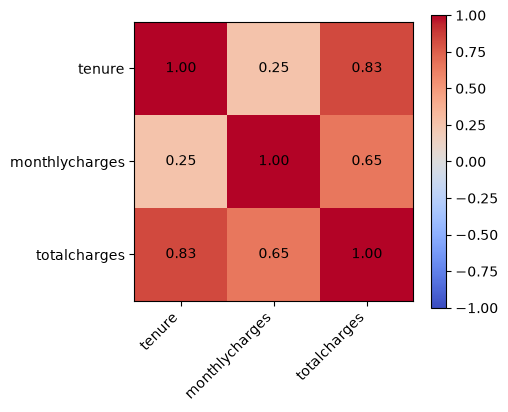

In [25]:
fig, ax = plt.subplots(figsize=(4.5, 3.8))
im = ax.imshow(corr_matrix, vmin=-1, vmax=1, cmap='coolwarm')
ax.set_xticks(range(len(numerical)), numerical, rotation=45, ha='right')
ax.set_yticks(range(len(numerical)), numerical)
for i in range(len(numerical)):
    for j in range(len(numerical)):
        ax.text(j, i, f'{corr_matrix.iloc[i, j]:.2f}', ha='center', va='center')
fig.colorbar(im)
plt.show()

In [26]:
# with many features, don't eyeball the heatmap: rank the pairs.
# keep each pair once and skip the diagonal (a feature vs itself is always 1)
pairs = corr_matrix.abs().unstack()
pairs = pairs[pairs.index.get_level_values(0) < pairs.index.get_level_values(1)]
pairs.sort_values(ascending=False)

tenure          totalcharges    0.828268
monthlycharges  totalcharges    0.650913
                tenure          0.251072
dtype: float64

Note: mutual information (above) needs discrete variables, which is why we only ran it on the categorical columns. Correlation needs numbers, which is why we only ran it on the numerical ones. Each tool has a variable type it fits.

ONE HOT ENCODING

Imagine

gender , contract
f,2y
f,1y
m,m
m,1y
f,1y
m,m
m,2y

then we can draw a matrix 
gender      contract 
f,m         m,iy,2y

e fill with 1s and zeros correspnding to the row values above

for numerical attributes dictvectorizer will leave them intact

In [27]:
from sklearn.feature_extraction import DictVectorizer

In [28]:
df_train[['gender','contract']].iloc[:10]

,gender,contract
0,female,two_year
1,male,month-to-month
2,female,month-to-month
3,female,month-to-month
4,female,two_year
5,male,month-to-month
6,male,month-to-month
7,female,month-to-month
8,female,two_year
9,female,month-to-month


In [29]:
train_dicts=df_train[categorical+numerical].to_dict(orient='records')
dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_dicts)

In [30]:
val_dicts = df_val[categorical+numerical].to_dict(orient='records')
X_val = dv.transform(val_dicts) #so that we do not fit on val dataset

**[added] Inspect what one-hot encoding actually produced**

Never trust an encoding you haven't looked at. Check the shape and the column names.

In [31]:
print(X_train.shape)
dv.get_feature_names_out()

(4225, 45)


array(['contract=month-to-month', 'contract=one_year',
       'contract=two_year', 'dependents=no', 'dependents=yes',
       'deviceprotection=no', 'deviceprotection=no_internet_service',
       'deviceprotection=yes', 'gender=female', 'gender=male',
       'internetservice=dsl', 'internetservice=fiber_optic',
       'internetservice=no', 'monthlycharges', 'multiplelines=no',
       'multiplelines=no_phone_service', 'multiplelines=yes',
       'onlinebackup=no', 'onlinebackup=no_internet_service',
       'onlinebackup=yes', 'onlinesecurity=no',
       'onlinesecurity=no_internet_service', 'onlinesecurity=yes',
       'paperlessbilling=no', 'paperlessbilling=yes', 'partner=no',
       'partner=yes', 'paymentmethod=bank_transfer_(automatic)',
       'paymentmethod=credit_card_(automatic)',
       'paymentmethod=electronic_check', 'paymentmethod=mailed_check',
       'phoneservice=no', 'phoneservice=yes', 'seniorcitizen',
       'streamingmovies=no', 'streamingmovies=no_internet_service',

Things to notice:
- every categorical value became its own 0/1 column, named `column=value`
- `DictVectorizer` one-hot encodes **string values only**. Numbers pass through as they are. `seniorcitizen` is in our `categorical` list but it is already 0/1 (an int), so it stays a single column instead of being split in two. The result is equivalent, but remember it: **the dtype decides how a column is encoded, not the name of the list you put it in**.
- `dv.fit_transform` on train, `dv.transform` on val/test. The encoder learns its columns from train only.

LOGISTIC REGRESSION

**[added] The idea**

Linear regression predicts a number: `g(x) = w0 + w1*x1 + ... + wn*xn`.

Logistic regression takes that same linear score `z` and passes it through the **sigmoid**, so the output is between 0 and 1 and can be read as P(churn):

    p = sigmoid(w0 + w·x),   sigmoid(z) = 1 / (1 + e^(-z))

- z = 0 gives p = 0.5, a large positive z gives p near 1, a large negative z gives p near 0
- training means finding `w0` and `w` so these probabilities match the real 0/1 labels

In [32]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

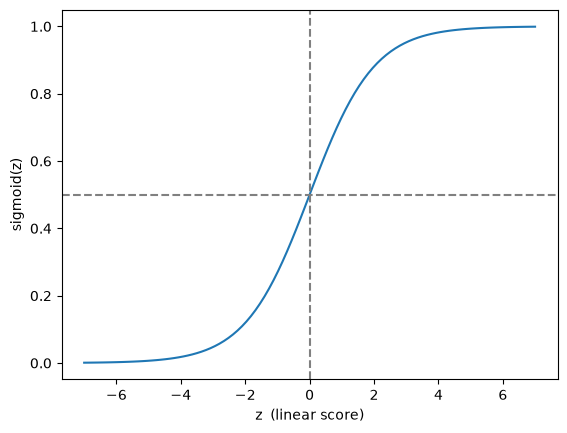

In [33]:
z = np.linspace(-7, 7, 101)

plt.plot(z, sigmoid(z))
plt.axhline(0.5, color='gray', linestyle='--')
plt.axvline(0, color='gray', linestyle='--')
plt.xlabel('z  (linear score)')
plt.ylabel('sigmoid(z)')
plt.show()

**[added] Train with scikit-learn**

Fit on **train**, evaluate on **val**. Never evaluate on the data the model was fit on.

On the solver: the default solver (`lbfgs`) emits convergence warnings on this data because `totalcharges` is in the thousands while the other columns are 0/1. `solver='liblinear'` converges cleanly on a dataset this size, and `random_state` makes the result repeatable. **If a homework question specifies solver, C, max_iter or random_state, use exactly those values**, because different settings give slightly different accuracies.

In [34]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

model = LogisticRegression(solver='liblinear', random_state=1)
model.fit(X_train, y_train)

y_pred = model.predict(X_val)
accuracy = accuracy_score(y_val, y_pred)
print(f"Accuracy: {accuracy}")

Accuracy: 0.8055358410220014


**[added] Is that accuracy actually good? Compare to a baseline**

Churn is imbalanced (about 73% stay). A model that ignores every feature and always answers "no churn" already scores that high, so the accuracy number means nothing until you compare it to this baseline.

In [35]:
baseline_accuracy = 1 - y_val.mean()   # share of customers who did not churn
print(f"model: {accuracy:.4f}   |   always predict 'no churn': {baseline_accuracy:.4f}")

model: 0.8055   |   always predict 'no churn': 0.7260


**[added] Hard predictions vs soft predictions**

- `predict_proba` returns probabilities. Column 0 is P(no churn), column 1 is P(churn).
- `predict` returns 0/1. It is simply `probability >= 0.5`.

In [36]:
y_proba = model.predict_proba(X_val)[:, 1]
print(y_proba[:5].round(3))

churn_decision = (y_proba >= 0.5)
print('accuracy from probabilities:', (churn_decision == y_val).mean())
print('identical to model.predict:', (churn_decision == model.predict(X_val)).all())

[0.007 0.21  0.221 0.575 0.217]
accuracy from probabilities: 0.8055358410220014
identical to model.predict: True


**[added] The 0.5 threshold is a choice, not a law**

Moving the threshold trades one kind of mistake for another. Accuracy alone hides that, which is why the next module introduces precision, recall and ROC AUC.

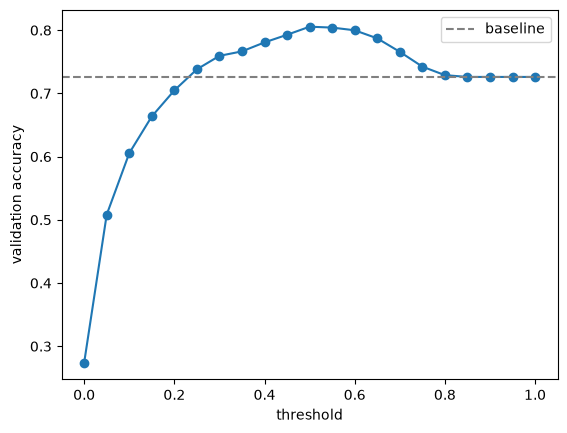

In [37]:
thresholds = np.linspace(0, 1, 21)
accuracies = [((y_proba >= t) == y_val).mean() for t in thresholds]

plt.plot(thresholds, accuracies, marker='o')
plt.axhline(baseline_accuracy, color='gray', linestyle='--', label='baseline')
plt.xlabel('threshold')
plt.ylabel('validation accuracy')
plt.legend()
plt.show()

**[added] Model interpretation: what did the model learn?**

A logistic regression is just an intercept `w0` and one weight per column. You can read them.

In [38]:
feature_names = dv.get_feature_names_out()
print('intercept (w0):', model.intercept_[0].round(3))

coefficients = pd.Series(model.coef_[0], index=feature_names).sort_values()
pd.concat([coefficients.head(5), coefficients.tail(5)]).round(3)

intercept (w0): -0.122


contract=two_year             -0.671
internetservice=dsl           -0.376
phoneservice=yes              -0.255
paperlessbilling=no           -0.249
multiplelines=no              -0.248
techsupport=no                 0.170
seniorcitizen                  0.199
onlinesecurity=no              0.217
internetservice=fiber_optic    0.357
contract=month-to-month        0.607
dtype: float64

- a **positive** weight pushes the prediction toward churn, a **negative** weight pushes away from it
- compare magnitudes carefully. `totalcharges` is measured in thousands, so its weight is tiny even if the feature matters. Weights are only comparable between columns on a similar scale (the 0/1 one-hot columns are comparable with each other)

**[added] Predict by hand**

`predict_proba` is nothing more than the formula from the top of this section.

In [39]:
x = X_val[0]
z = model.intercept_[0] + x @ model.coef_[0]

print('z                =', round(z, 4))
print('sigmoid(z)       =', round(sigmoid(z), 4))
print('predict_proba[0] =', round(y_proba[0], 4))

z                = -4.9045
sigmoid(z)       = 0.0074
predict_proba[0] = 0.0074


**[added] Refactor into reusable functions**

The same steps (dicts → DictVectorizer → fit → predict) are about to run many times, once per experiment. Put them in functions so each experiment is a short loop instead of copy-pasted cells.

`features` lets us train on a subset of columns, and `C` is the regularization strength.

In [40]:
def train(df, y, features=None, C=1.0):
    if features is None:
        features = categorical + numerical
    dicts = df[features].to_dict(orient='records')

    dv = DictVectorizer(sparse=False)
    X = dv.fit_transform(dicts)

    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000, random_state=1)
    model.fit(X, y)
    return dv, model


def predict(df, dv, model, features=None):
    if features is None:
        features = categorical + numerical
    dicts = df[features].to_dict(orient='records')
    X = dv.transform(dicts)
    return model.predict_proba(X)[:, 1]


def accuracy_at(y_true, y_proba, threshold=0.5):
    return ((y_proba >= threshold) == y_true).mean()

In [41]:
# sanity check: the refactor must reproduce the earlier number
dv, model = train(df_train, y_train)
y_proba = predict(df_val, dv, model)
base_acc = accuracy_at(y_val, y_proba)
print(round(base_acc, 4), '| earlier:', round(accuracy, 4))

0.8055 | earlier: 0.8055


**[added] Experiment 1: feature elimination**

Which features does the model barely need? Train with all features to get a reference accuracy. Then, for each feature: remove it, retrain, and compare the new validation accuracy to the reference.

- `diff = reference - new accuracy`. A **small** diff means the feature adds little. A **negative** diff means accuracy went *up* without it.
- the differences are tiny (third or fourth decimal), so rounding and the exact definition matter. If a homework question says "smallest difference", read whether it means the smallest signed value or the smallest absolute value, and how it wants the numbers rounded.

In [42]:
all_features = categorical + numerical
rows = []

for f in all_features:
    subset = [x for x in all_features if x != f]
    dv_f, model_f = train(df_train, y_train, features=subset)
    acc_f = accuracy_at(y_val, predict(df_val, dv_f, model_f, features=subset))
    rows.append({'dropped': f, 'accuracy': acc_f, 'diff': base_acc - acc_f})

elimination = pd.DataFrame(rows).sort_values('diff')
elimination.round(4)

,dropped,accuracy,diff
0,gender,0.8070,-0.0014
7,onlinesecurity,0.8070,-0.0014
9,deviceprotection,0.8070,-0.0014
16,tenure,0.8062,-0.0007
3,dependents,0.8048,0.0007
4,phoneservice,0.8041,0.0014
17,monthlycharges,0.8041,0.0014
2,partner,0.8034,0.0021
15,paymentmethod,0.8034,0.0021
18,totalcharges,0.8034,0.0021


**[added] Experiment 2: regularization strength `C`**

Regularization penalizes large weights so the model can't fit noise in the training data.

- in scikit-learn, `C` is the **inverse** of the strength: **small C = strong regularization**, large C = weak regularization
- strong regularization shrinks weights toward 0. Too strong and the model underfits (it approaches the baseline), too weak and it can overfit
- search `C` on a **log scale**, because its effect is multiplicative. Pick the best value using the **validation** set, never the test set
- if several values tie (after rounding the way the question asks), the question will say how to break the tie. Read it.

In [43]:
Cs = [10.0**p for p in range(-6, 3)]   # 1e-6, 1e-5, ... , 100
rows = []

for C in Cs:
    dv_c, model_c = train(df_train, y_train, C=C)
    acc_c = accuracy_at(y_val, predict(df_val, dv_c, model_c))
    rows.append({'C': C, 'val_accuracy': acc_c})

c_results = pd.DataFrame(rows)
c_results['val_accuracy'] = c_results['val_accuracy'].round(4)
c_results

,C,val_accuracy
0,0.000001,0.7452
1,0.000010,0.7622
2,0.000100,0.7800
3,0.001000,0.7899
4,0.010000,0.7984
5,0.100000,0.8048
6,1.000000,0.8055
7,10.000000,0.8041
8,100.000000,0.8041


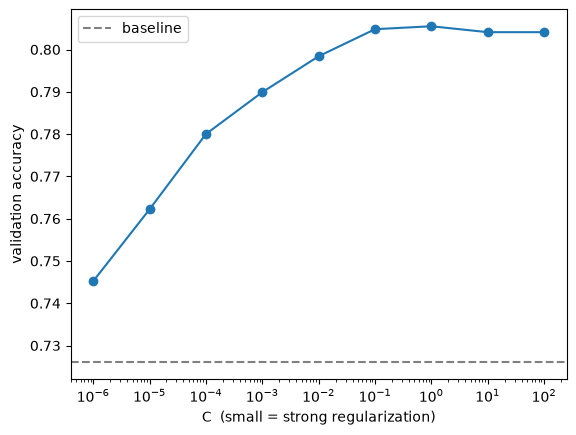

In [44]:
plt.plot(c_results['C'], c_results['val_accuracy'], marker='o')
plt.axhline(baseline_accuracy, color='gray', linestyle='--', label='baseline')
plt.xscale('log')
plt.xlabel('C  (small = strong regularization)')
plt.ylabel('validation accuracy')
plt.legend()
plt.show()

**[added] Final evaluation: touch the test set once**

You now have every decision you need: features, `C`, threshold. Retrain on **train + val** (more data, same settings) and evaluate on test exactly once. If you change your model after looking at this number, the test set is no longer a fair judge.

In [45]:
best_C = c_results.loc[c_results['val_accuracy'].idxmax(), 'C']   # first max = smallest C on ties
print('best C:', best_C)

y_full_train = df_full_train.churn.values
dv_final, model_final = train(df_full_train, y_full_train, C=best_C)

y_test_proba = predict(df_test, dv_final, model_final)
print('test accuracy:', round(accuracy_at(y_test, y_test_proba), 4))
print('test baseline:', round(1 - y_test.mean(), 4))

best C: 1.0
test accuracy: 0.8126
test baseline: 0.753


In [46]:
# where does the model go wrong? accuracy hides the type of mistake
pd.crosstab(y_test, y_test_proba >= 0.5, rownames=['actual churn'], colnames=['predicted churn'])

predicted churn,False,True
actual churn,,
0,940,121
1,143,205


**[added] Using the model on one customer**

This is what a deployed model does: take one record, encode it with the **already fitted** `DictVectorizer`, return a probability. (Module 5 wraps exactly this in a web service.)

In [47]:
customer = df_test.iloc[0][categorical + numerical].to_dict()
customer

{'gender': 'female',
 'seniorcitizen': 0,
 'partner': 'no',
 'dependents': 'no',
 'phoneservice': 'yes',
 'multiplelines': 'no',
 'internetservice': 'dsl',
 'onlinesecurity': 'yes',
 'onlinebackup': 'no',
 'deviceprotection': 'yes',
 'techsupport': 'yes',
 'streamingtv': 'yes',
 'streamingmovies': 'yes',
 'contract': 'one_year',
 'paperlessbilling': 'yes',
 'paymentmethod': 'bank_transfer_(automatic)',
 'tenure': 41,
 'monthlycharges': 79.85,
 'totalcharges': 3320.75}

In [48]:
X_customer = dv_final.transform([customer])
print('P(churn) =', model_final.predict_proba(X_customer)[0, 1].round(3))
print('actual   =', y_test[0])

P(churn) = 0.059
actual   = 0


---
## [added] Adapting this workflow to a new dataset

The homework dataset is different, so the steps stay but the details change. Work down this list:

1. **Look at the columns first.** Identify the target and any ID-like columns that must not be features (`customerid` here).
2. **Normalize names and strings.** Lowercase and replace spaces with underscores, as in the top of this notebook.
3. **Missing values: decide per column type, and write the rule down.** A common pattern is numeric columns → `0` (or median), categorical columns → a placeholder string such as `'NA'`. Any statistic you fill with (mean, median, mode) must come from **train only**. Always run `df.isnull().sum()` before and after.
4. **Target to 0/1** (`(df.target == 'yes').astype(int)`), then **split** train/val/test with a fixed `random_state`.
5. **Take the target out of the feature frames**, and check `dtypes`. A column's dtype decides how it is treated (see the `seniorcitizen` note).
6. **Define `numerical` and `categorical` lists explicitly.**
7. **EDA and feature importance on train only:** target rate, group means (diff and risk ratio), mutual information for categoricals, `corrwith(target)` for numeric-vs-target, `.corr()` for numeric-vs-numeric.
8. **Encode** with `DictVectorizer`: `fit_transform` on train, `transform` on val and test.
9. **Fit, evaluate on val, compare to the baseline.**
10. **Experiments:** feature elimination, `C` sweep, threshold.
11. **Retrain on train + val, evaluate on test once.**

**Mistakes this list prevents:** filling missing values with statistics computed on all the data (leakage), fitting the encoder on val/test, touching test early, comparing accuracy to nothing, and trusting an encoding you never inspected.

## [added] Your turn

Try these in a new notebook **without scrolling up**. Where you get stuck is what to review.

1. Rebuild steps 1-9 of the list above on the homework dataset. Write a one-line plan in markdown for each step before the code.
2. **Predict before you run:** with `C` very small, will accuracy move toward the baseline or away from it? Then check.
3. Pick any feature from the elimination table and explain, using the EDA cells, *why* removing it hurt or didn't.
4. Take any customer from `df_val`, compute `z` by hand, and explain in words what each of the biggest weights contributes.